# MsPacMan · Q-table og PPO med poengbonus

Dette oppfølgingsforsøket trener Q-tabell og PPO i B med 32 768 miljøinteraksjoner per agent som standard. Begge får 0,25 × opptjente spillpoeng / 2 000 på hvert steg, og +1 når summen når 2 000. Treningen bruker tre felles frø, og hver frosne modell evalueres på 200 testepisoder.

Treningen starter med nye modeller. Underveismålinger hver 4 096. interaksjon inkluderer 16 384. Etter sluttevaluering kan de samme agentene fortsette til 65 536 hvis notebook-kjernen fortsatt er aktiv. Sett eventuelt FIRST_BUDGET til 16_384 hvis du vil ha en full sluttevaluering ved det første målepunktet også.

Rapporten viser sammenligning mellom algoritmene ved likt budsjett, og sammenligner Q-tabellen med den tidligere poengbonuskjøringen ved 16 384 når konfigurasjonene samsvarer. Sammenligningen mellom algoritmene omfatter også ulike observasjoner og evalueringsregler. Q-tabellen bruker RAM-avledede tilstander og velger grådig, mens PPO bruker bildestabler og sampler handlinger.

Kjør notebooken med Python 3.12 fra oppgavemappen. Dashboardet viser hvert evaluert budsjett som en egen kjøring med avspillingsspor.

In [1]:
%pip install "gymnasium[atari]==1.2.3" "ale-py==0.11.2" "opencv-python-headless>=4.10,<5" "pandas>=2.2,<3" "matplotlib>=3.9,<4" "joblib>=1.4,<2" "torch==2.7.1"

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from dataclasses import asdict, dataclass
from datetime import datetime, timezone
from functools import partial
from importlib.metadata import version
from pathlib import Path
from time import perf_counter
import gzip
import json
import os
import platform

import ale_py
import gymnasium as gym
from gymnasium.wrappers import FrameStackObservation, RecordEpisodeStatistics, ResizeObservation, TimeLimit
from IPython.display import display
from joblib import Parallel, delayed, parallel_config
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.distributions import Categorical

gym.register_envs(ale_py)


ENV_ID = "ALE/MsPacman-v5"
SUCCESS_POINTS = 2_000
MAX_EPISODE_STEPS = 1_024
FRAME_SKIP = 4
OBS_SHAPE = (4, 42, 42)
TRAINING_SEEDS = (42, 43, 44)
MONITOR_SEEDS = tuple(range(100_000, 100_008))
TEST_SEEDS = tuple(range(200_000, 200_200))
CHECKPOINT_EVERY = 4_096
MILESTONES = (16_384, 32_768, 65_536)
FIRST_BUDGET = 32_768
TRAIN_ENVS = 8
EVAL_ENVS = 24
EVAL_WORKERS = min(4, os.cpu_count() or 1)
BASELINE_DIR = Path("part2_results/20261121T225354155485Z")
SCORE_BONUS = 0.25
GAMMA = 0.99
Q_TABLE = dict(alpha=0.15, epsilon_start=1.0, epsilon_end=0.10,
               exploration_steps=12_288, position_bin=12, ghost_radius=24)
PPO = dict(lr=2.5e-4, rollout_steps=64, gae_lambda=0.95, clip=0.20,
           epochs=4, batch_size=64, entropy_coef=0.01, value_coef=0.5,
           max_grad_norm=0.5)
ALGORITHMS = ("Q-table", "PPO")
SETTING = "B"
PARAMS = {"Q-table": Q_TABLE, "PPO": PPO}
POLICIES = {"Q-table": "greedy Q-table (current direction on ties when available)",
            "PPO": "sampled categorical"}
DEVICE = torch.device("cpu")
TORCH_THREADS = 1
torch.set_num_threads(TORCH_THREADS)


@dataclass(frozen=True)
class Setting:
    sticky: float
    step_penalty: float = 0.0
    maze: int = 0
    score_bonus: float = 0.0


SETTINGS = {SETTING: Setting(sticky=0.25, score_bonus=SCORE_BONUS)}
assert np.isfinite(SCORE_BONUS) and SCORE_BONUS > 0
assert ALGORITHMS and len(ALGORITHMS) == len(set(ALGORITHMS)) and set(ALGORITHMS) <= PARAMS.keys()
assert FIRST_BUDGET in MILESTONES
assert CHECKPOINT_EVERY % (TRAIN_ENVS * PPO["rollout_steps"]) == 0
assert all(total % CHECKPOINT_EVERY == 0 for total in MILESTONES)

In [3]:
class MazeStart(gym.Wrapper):
    """Select the ROM's starting maze before the initial frame is stacked."""

    def __init__(self, env, maze):
        super().__init__(env)
        self.maze = maze
        self.ale = self.unwrapped.ale
        self.noop = self.unwrapped.get_action_meanings().index("NOOP")

    def reset(self, *, seed=None, options=None):
        self.env.reset(seed=seed, options=options)
        if self.maze != 0:
            self.ale.setRAM(0, self.maze)
        observation, points, terminated, truncated, info = self.env.step(self.noop)
        if points != 0 or terminated or truncated or self.ale.getRAM()[0] != self.maze:
            raise RuntimeError("Unexpected MsPacman state during maze reset.")
        return observation, info


class ScoreGoal(gym.Wrapper):
    def __init__(self, env, setting):
        super().__init__(env)
        self.setting = setting
        self.ale = self.unwrapped.ale

    def reset(self, **kwargs):
        self.score = 0.0
        return self.env.reset(**kwargs)

    def step(self, action):
        obs, points, game_over, timeout, info = self.env.step(action)
        self.score += float(points)
        success = self.score >= SUCCESS_POINTS
        maze_exit = int(self.ale.getRAM()[0]) != self.setting.maze
        terminated = bool(success or game_over or maze_exit)
        truncated = bool(timeout and not terminated)
        outcome = ("success" if success else "game_over" if game_over else
                   "maze_exit" if maze_exit else "timeout" if truncated else "in_progress")
        reward = (float(success) + self.setting.score_bonus * float(points) / SUCCESS_POINTS
                  - self.setting.step_penalty)
        info.update(raw_points=float(points), raw_score=self.score, outcome=outcome)
        return obs, reward, terminated, truncated, info


def tabular_state(ram):
    """Encode coarse player position, heading and the nearest nearby ghost."""
    x, y = int(ram[10]), int(ram[16])
    heading = int(ram[56]) & 3
    sector = 9
    if ram[47] > 0:
        ghosts = range(1 + min(int(ram[19]), 3))
        offsets = [(int(ram[6 + i]) - x, int(ram[12 + i]) - y) for i in ghosts]
        dx, dy = min(offsets, key=lambda offset: abs(offset[0]) + abs(offset[1]))
        if abs(dx) + abs(dy) <= Q_TABLE["ghost_radius"]:
            sx = int(dx > 0) - int(dx < 0)
            sy = int(dy > 0) - int(dy < 0)
            sector = (sx + 1) * 3 + sy + 1
    position_bin = Q_TABLE["position_bin"]
    return x // position_bin, y // position_bin, heading, sector


class TabularObservation(gym.ObservationWrapper):
    def __init__(self, env):
        super().__init__(env)
        positions = 255 // Q_TABLE["position_bin"] + 1
        self.observation_space = gym.spaces.MultiDiscrete([positions, positions, 4, 10])

    def observation(self, observation):
        return np.asarray(tabular_state(self.unwrapped.ale.getRAM()), dtype=np.int64)


def build_environment(setting_name, algorithm=None):
    setting = SETTINGS[setting_name]
    env = gym.make(ENV_ID, obs_type="grayscale", frameskip=FRAME_SKIP,
                   repeat_action_probability=setting.sticky, full_action_space=False)
    env = MazeStart(env, setting.maze)
    env = ResizeObservation(env, OBS_SHAPE[1:])
    env = FrameStackObservation(env, stack_size=OBS_SHAPE[0])
    env = TimeLimit(env, max_episode_steps=MAX_EPISODE_STEPS)
    env = RecordEpisodeStatistics(ScoreGoal(env, setting))
    return TabularObservation(env) if algorithm == "Q-table" else env


for algorithm in ALGORITHMS:
    with build_environment(SETTING, algorithm) as probe:
        initial, _ = probe.reset(seed=900_001)
        assert probe.observation_space.contains(initial)
        ACTION_NAMES = probe.unwrapped.get_action_meanings()
        assert [ACTION_NAMES[i] for i in (1, 2, 4, 3)] == ["UP", "RIGHT", "DOWN", "LEFT"]

In [4]:
class TrainingBatch:
    def __init__(self, setting, seed, algorithm):
        self.env = gym.vector.SyncVectorEnv(
            [partial(build_environment, setting, algorithm) for _ in range(TRAIN_ENVS)],
            autoreset_mode=gym.vector.AutoresetMode.DISABLED,
        )
        env_seeds = [seed * 1_000 + i for i in range(TRAIN_ENVS)]
        self.obs, _ = self.env.reset(seed=env_seeds)
        self.actions = self.env.single_action_space.n
        self.interactions = 0
        self.episodes = []

    def step(self, actions):
        next_obs, rewards, terminated, truncated, info = self.env.step(actions)
        self.interactions += TRAIN_ENVS
        done = terminated | truncated
        for i in np.flatnonzero(done):
            self.episodes.append(dict(interactions=self.interactions, env_index=int(i),
                                      episode_return=float(info["episode"]["r"][i]),
                                      length=int(info["episode"]["l"][i]),
                                      raw_score=float(info["raw_score"][i]),
                                      outcome=str(info["outcome"][i])))
        if done.any():
            self.obs, _ = self.env.reset(options={"reset_mask": done})
        else:
            self.obs = next_obs
        return next_obs, rewards, terminated, done


class TabularQModel:
    def __init__(self, action_count):
        self.zero = np.zeros(action_count, dtype=np.float64)
        self.q = {}

    def values(self, state):
        return self.q.get(tuple(state), self.zero)

    def greedy(self, state):
        values = self.values(state)
        best = int(values.argmax())
        forward = (1, 2, 4, 3)[state[2]]  # UP, RIGHT, DOWN, LEFT in the ALE minimal action space.
        return forward if values[forward] == values[best] else best

    def save(self, path):
        keys = np.asarray(list(self.q), dtype=np.int16).reshape(-1, 4)
        values = np.asarray(list(self.q.values()), dtype=np.float64).reshape(-1, len(self.zero))
        np.savez_compressed(path, keys=keys, values=values)


class TabularQTrainer:
    def __init__(self, action_count, seed):
        self.model = TabularQModel(action_count)
        self.rng = np.random.default_rng(seed)
        self.updates = 0

    def train_until(self, batch, stop):
        cfg = Q_TABLE
        while batch.interactions < stop:
            observations = batch.obs
            epsilon = np.interp(batch.interactions, [0, cfg["exploration_steps"]],
                                [cfg["epsilon_start"], cfg["epsilon_end"]])
            actions = np.array([self.rng.integers(batch.actions) if self.rng.random() < epsilon
                                else self.model.greedy(state) for state in observations])
            next_obs, rewards, terminated, _ = batch.step(actions)
            for state, action, reward, next_state, terminal in zip(observations, actions, rewards, next_obs, terminated):
                key = tuple(state)
                if key not in self.model.q:
                    self.model.q[key] = self.model.zero.copy()
                values = self.model.q[key]
                future = 0.0 if terminal else self.model.values(next_state).max()
                values[action] += cfg["alpha"] * (reward + GAMMA * future - values[action])
                self.updates += 1


class AtariEncoder(nn.Sequential):
    def __init__(self):
        super().__init__(nn.Conv2d(4, 16, 6, stride=4), nn.ReLU(),
                         nn.Conv2d(16, 32, 4, stride=2), nn.ReLU(), nn.Flatten(),
                         nn.Linear(32 * 4 * 4, 128), nn.ReLU())

    def forward(self, pixels):
        return super().forward(pixels.float() / 255.0)



class AtariActorCritic(nn.Module):
    def __init__(self, action_count):
        super().__init__()
        self.encoder = AtariEncoder()
        self.actor = nn.Linear(128, action_count)
        self.critic = nn.Linear(128, 1)
        nn.init.orthogonal_(self.actor.weight, gain=0.01)
        nn.init.zeros_(self.actor.bias)
        nn.init.orthogonal_(self.critic.weight)
        nn.init.zeros_(self.critic.bias)

    def forward(self, pixels):
        features = self.encoder(pixels)
        return self.actor(features), self.critic(features).squeeze(-1)


def tensor(array):
    return torch.as_tensor(array, device=DEVICE)



def gae_targets(rewards, values, next_values, terminated, done):
    """Bootstrap at time limits, but stop GAE at any episode boundary."""
    advantages = torch.empty_like(values)
    gae = torch.zeros_like(values[0])
    for t in range(len(values) - 1, -1, -1):
        delta = rewards[t] + GAMMA * (~terminated[t]) * next_values[t] - values[t]
        gae = delta + GAMMA * PPO["gae_lambda"] * (~done[t]) * gae
        advantages[t] = gae
    return advantages, advantages + values


class PPOTrainer:
    def __init__(self, action_count, seed):
        self.rng = np.random.default_rng(seed)
        self.action_rng = torch.Generator(device=DEVICE).manual_seed(seed)
        with torch.random.fork_rng(devices=[]):
            torch.manual_seed(seed)
            self.model = AtariActorCritic(action_count).to(DEVICE)
        self.optimizer = torch.optim.Adam(self.model.parameters(), lr=PPO["lr"], eps=1e-5)
        self.updates = 0

    @torch.no_grad()
    def collect(self, batch):
        rollout = []
        for _ in range(PPO["rollout_steps"]):
            states = tensor(batch.obs)
            logits, values = self.model(states)
            distribution = Categorical(logits=logits)
            actions = torch.multinomial(distribution.probs, 1, replacement=True, generator=self.action_rng).squeeze(-1)
            next_obs, rewards, terminated, done = batch.step(actions.cpu().numpy())
            _, next_values = self.model(tensor(next_obs))
            rollout.append((states, actions, distribution.log_prob(actions), values,
                            next_values, tensor(rewards.astype(np.float32)),
                            tensor(terminated), tensor(done)))
        states, actions, logp, values, next_values, rewards, term, done = map(torch.stack, zip(*rollout))
        advantages, targets = gae_targets(rewards, values, next_values, term, done)
        advantages = (advantages - advantages.mean()) / (advantages.std(unbiased=False) + 1e-8)
        return tuple(x.flatten(0, 1) for x in (states, actions, logp, advantages, targets))

    def train_until(self, batch, stop):
        self.model.train()
        while batch.interactions < stop:
            states, actions, old_logp, advantages, targets = self.collect(batch)
            for _ in range(PPO["epochs"]):
                for indices in np.split(self.rng.permutation(len(actions)), len(actions) // PPO["batch_size"]):
                    logits, values = self.model(states[indices])
                    policy = Categorical(logits=logits)
                    ratio = (policy.log_prob(actions[indices]) - old_logp[indices]).exp()
                    adv = advantages[indices]
                    clipped = ratio.clamp(1 - PPO["clip"], 1 + PPO["clip"])
                    actor_loss = -torch.minimum(ratio * adv, clipped * adv).mean()
                    value_loss = F.mse_loss(values, targets[indices])
                    loss = actor_loss + PPO["value_coef"] * value_loss - PPO["entropy_coef"] * policy.entropy().mean()
                    self.optimizer.zero_grad(set_to_none=True)
                    loss.backward()
                    nn.utils.clip_grad_norm_(self.model.parameters(), PPO["max_grad_norm"])
                    self.optimizer.step()
                    self.updates += 1

In [5]:
@torch.inference_mode()
def evaluate(model, algorithm, setting, seeds, record_actions=False):
    if algorithm != "Q-table":
        model.eval()
    results, traces = [], []
    start = perf_counter()
    envs = [build_environment(setting, algorithm) for _ in range(min(EVAL_ENVS, len(seeds)))]
    try:
        # Separate generators keep PPO's actions reproducible across batch sizes.
        uniforms = [np.random.default_rng([seed, 29]).random(MAX_EPISODE_STEPS) for seed in seeds]
        for offset in range(0, len(seeds), len(envs)):
            batch_seeds = seeds[offset:offset + len(envs)]
            ob = {i: envs[i].reset(seed=seed)[0] for i, seed in enumerate(batch_seeds)}
            action_logs = [[] for _ in batch_seeds]
            seen = np.zeros(len(batch_seeds), dtype=int)
            for step in range(MAX_EPISODE_STEPS):
                if not ob:
                    break
                slots = list(ob)
                if algorithm == "Q-table":
                    actions = [model.greedy(ob[i]) for i in slots]
                    for i in slots:
                        seen[i] += tuple(ob[i]) in model.q
                else:
                    logits, _ = model(tensor(np.stack(list(ob.values()))))
                    cdf = logits.softmax(dim=1).cumsum(dim=1).numpy()
                    cdf[:, -1] = 1.0
                    draws = [uniforms[offset + i][step] for i in slots]
                    actions = (np.asarray(draws)[:, None] >= cdf).sum(axis=1)
                for i, action in zip(slots, actions):
                    ob[i], _, terminated, truncated, info = envs[i].step(int(action))
                    if record_actions:
                        action_logs[i].append(int(action))
                    if terminated or truncated:
                        seed = batch_seeds[i]
                        results.append(dict(eval_seed=seed, length=int(info["episode"]["l"]),
                                            episode_return=float(info["episode"]["r"]),
                                            raw_score=float(info["raw_score"]), outcome=info["outcome"]))
                        if algorithm == "Q-table":
                            results[-1]["known_state_steps"] = int(seen[i])
                        if record_actions:
                            traces.append(dict(eval_seed=seed, actions=action_logs[i]))
                        del ob[i]
            assert not ob, "Gymnasium TimeLimit should end every episode in the batch."
    finally:
        for env in envs:
            env.close()
    return sorted(results, key=lambda row: row["eval_seed"]), traces, perf_counter() - start


def load_model(algorithm, path):
    if algorithm == "Q-table":
        model = TabularQModel(len(ACTION_NAMES))
        with np.load(path, allow_pickle=False) as checkpoint:
            model.q = {tuple(key): values.copy() for key, values in
                       zip(checkpoint["keys"], checkpoint["values"], strict=True)}
        return model
    model = AtariActorCritic(len(ACTION_NAMES)).to(DEVICE)
    model.load_state_dict(torch.load(path, map_location=DEVICE, weights_only=True))
    return model.eval()


def summarize(episodes):
    success = [row["length"] for row in episodes if row["outcome"] == "success"]
    failure = [row["length"] for row in episodes if row["outcome"] != "success"]
    coverage = {}
    if "known_state_steps" in episodes[0]:
        coverage["known_state_rate"] = sum(row["known_state_steps"] for row in episodes) / sum(
            row["length"] for row in episodes)
    return dict(**coverage, episodes=len(episodes), successes=len(success), failures=len(failure),
                success_rate=len(success) / len(episodes), failure_rate=len(failure) / len(episodes),
                mean_return=float(np.mean([row["episode_return"] for row in episodes])),
                mean_raw_score=float(np.mean([row["raw_score"] for row in episodes])),
                success_length=float(np.mean(success)) if success else np.nan,
                failure_length=float(np.mean(failure)) if failure else np.nan,
                eval_interactions=sum(row["length"] for row in episodes))



def run_test(run, setting, output):
    torch.set_num_threads(TORCH_THREADS)
    gym.register_envs(ale_py)
    algorithm = run["algorithm"]
    eval_id = f"{run['run_id']}__eval-{setting}"
    model = load_model(algorithm, output / run["checkpoint"])
    rows, traces, elapsed = evaluate(model, algorithm, setting, TEST_SEEDS, record_actions=True)
    folder = output / run["run_id"]
    pd.DataFrame(rows).assign(eval_id=eval_id).to_csv(folder / f"evaluation_{setting}.csv", index=False)
    with gzip.open(folder / f"actions_{setting}.jsonl.gz", "wt", encoding="utf-8") as stream:
        for trace in sorted(traces, key=lambda row: row["eval_seed"]):
            stream.write(json.dumps(trace, separators=(",", ":")) + "\n")
    print(f"{eval_id}: {len(rows)} held-out episodes in {elapsed:.1f} s", flush=True)
    return dict(eval_id=eval_id, setting=setting, policy=POLICIES[algorithm], eval_seconds=elapsed,
                **run, **summarize(rows))

In [6]:
def cpu_name():
    if platform.system() == "Windows":
        import winreg
        with winreg.OpenKey(winreg.HKEY_LOCAL_MACHINE, r"HARDWARE\DESCRIPTION\System\CentralProcessor\0") as key:
            return winreg.QueryValueEx(key, "ProcessorNameString")[0].strip()
    if Path("/proc/cpuinfo").exists():
        for line in Path("/proc/cpuinfo").read_text().splitlines():
            if line.startswith("model name"):
                return line.split(":", 1)[1].strip()
    return platform.processor() or platform.machine()


def experiment_settings(budget):
    return dict(env_id=ENV_ID, success_points=SUCCESS_POINTS, max_episode_steps=MAX_EPISODE_STEPS,
                observation_shape=OBS_SHAPE, action_names=ACTION_NAMES, frame_skip=FRAME_SKIP,
                settings={SETTING: asdict(SETTINGS[SETTING])}, training_seeds=TRAINING_SEEDS,
                monitor_seeds=MONITOR_SEEDS, test_seeds=TEST_SEEDS, interaction_budget=budget,
                checkpoint_every=CHECKPOINT_EVERY, gamma=GAMMA, algorithms={name: PARAMS[name] for name in ALGORITHMS},
                eval_modes={name: POLICIES[name] for name in ALGORITHMS},
                hardware=dict(device="cpu", cpu=cpu_name(), logical_cpus=os.cpu_count(),
                              training_envs=TRAIN_ENVS, evaluation_batch_size=EVAL_ENVS,
                              evaluation_workers=EVAL_WORKERS),
                software={name: version(name) for name in ("gymnasium", "ale-py", "numpy", "torch",
                          "opencv-python-headless", "pandas", "matplotlib", "joblib")},
                python=platform.python_version(), operating_system=platform.platform())


class AgentProgress:
    def __init__(self, algorithm, seed):
        self.seed = seed
        self.algorithm = algorithm
        self.run_id = f"{SETTING}-{algorithm}-s{seed}"
        self.batch = TrainingBatch(SETTING, seed, algorithm)
        trainer_class = TabularQTrainer if algorithm == "Q-table" else PPOTrainer
        self.trainer = trainer_class(self.batch.actions, seed)
        self.training_seconds = 0.0
        self.curve = []
        self.monitor_episodes = []

    def advance_to(self, budget):
        monitored = {row["interactions"] for row in self.curve}
        for target in range(0, budget + 1, CHECKPOINT_EVERY):
            if target in monitored:
                continue
            if self.batch.interactions < target:
                start = perf_counter()
                try:
                    self.trainer.train_until(self.batch, target)
                finally:
                    self.training_seconds += perf_counter() - start
            assert self.batch.interactions == target
            episodes, _, elapsed = evaluate(self.trainer.model, self.algorithm, SETTING, MONITOR_SEEDS)
            self.monitor_episodes.extend(dict(row, run_id=self.run_id, interactions=target) for row in episodes)
            record = dict(run_id=self.run_id, setting=SETTING, algorithm=self.algorithm, train_seed=self.seed,
                          interactions=target, training_seconds=self.training_seconds,
                          monitor_seconds=elapsed, **summarize(episodes))
            self.curve.append(record)
            print(f"{self.run_id}: {target:,} interactions, monitor score {record['mean_raw_score']:.1f}", flush=True)

    def save(self, output):
        folder = output / self.run_id
        folder.mkdir()
        checkpoint = folder / ("q_table.npz" if self.algorithm == "Q-table" else "model.pt")
        if self.algorithm == "Q-table":
            self.trainer.model.save(checkpoint)
        else:
            torch.save(self.trainer.model.state_dict(), checkpoint)
        pd.DataFrame(self.monitor_episodes).to_csv(folder / "monitor_episodes.csv", index=False)
        pd.DataFrame(self.batch.episodes).assign(run_id=self.run_id).to_csv(folder / "training_episodes.csv", index=False)
        config = dict(run_id=self.run_id, train_setting=SETTING, algorithm=self.algorithm, train_seed=self.seed,
                      training_interactions=self.batch.interactions, training_seconds=self.training_seconds,
                      optimizer_updates=self.trainer.updates, completed_training_episodes=len(self.batch.episodes),
                      params=PARAMS[self.algorithm], env_seeds=[self.seed * 1_000 + i for i in range(TRAIN_ENVS)],
                      checkpoint=checkpoint.relative_to(output).as_posix())
        if self.algorithm == "Q-table":
            config["q_table_states"] = len(self.trainer.model.q)
        (folder / "run.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
        return config


LEARNERS = {}
STAGES = {}


def train_to(budget):
    if budget not in MILESTONES:
        raise ValueError(f"Choose one of these budgets: {MILESTONES}.")
    if budget in STAGES:
        return STAGES[budget]
    if any(agent.batch.interactions > budget for agent in LEARNERS.values()):
        raise ValueError("The live agents are past this budget. Use an earlier saved stage.")
    for seed in TRAINING_SEEDS:
        for algorithm in ALGORITHMS:
            key = (algorithm, seed)
            if key not in LEARNERS:
                LEARNERS[key] = AgentProgress(algorithm, seed)
            LEARNERS[key].advance_to(budget)

    label = f"Poengbonus · {budget:,}".replace(",", " ")
    output = Path("part2_results") / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    output.mkdir(parents=True)
    manifest = dict(experiment_settings(budget), label=label, baseline_directory=str(BASELINE_DIR))
    (output / "experiment.json").write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")
    runs = [agent.save(output) for agent in LEARNERS.values()]
    learning = pd.DataFrame(row for agent in LEARNERS.values() for row in agent.curve)
    learning.to_csv(output / "learning_curves.csv", index=False)
    stage = dict(output=output, budget=budget, runs=runs, learning=learning)
    STAGES[budget] = stage
    print(output)
    return stage

In [7]:
def evaluate_stage(stage):
    output = stage["output"]
    completed = output / "per_agent.csv"
    if completed.is_file():
        return pd.read_csv(completed)
    with parallel_config(backend="loky", inner_max_num_threads=1):
        test_rows = Parallel(n_jobs=EVAL_WORKERS, verbose=5, max_nbytes=None)(
            delayed(run_test)(run, SETTING, output) for run in stage["runs"]
        )
    per_agent = pd.DataFrame(test_rows).sort_values(["algorithm", "train_seed"])
    assert len(per_agent) == len(ALGORITHMS) * len(TRAINING_SEEDS)
    assert (per_agent["training_interactions"] == stage["budget"]).all()
    assert (per_agent["episodes"] == len(TEST_SEEDS)).all()
    METRICS = ["success_rate", "failure_rate", "mean_return", "mean_raw_score",
               "success_length", "failure_length", "training_interactions", "training_seconds",
               "eval_interactions", "eval_seconds"]
    if "known_state_rate" in per_agent:
        METRICS.append("known_state_rate")
    groups = per_agent.groupby(["setting", "algorithm"])
    means = groups[METRICS].mean()
    variation = groups[METRICS].std(ddof=1)
    outcome_counts = groups[["success_length", "failure_length"]].count().rename(
        columns={"success_length": "agents_with_success", "failure_length": "agents_with_failure"})
    summary = means.join(variation.add_suffix("_sd")).join(outcome_counts)
    summary["n_agents"] = groups.size()
    summary.to_csv(output / "summary.csv")
    
    per_agent = per_agent.drop(columns=["params", "env_seeds"])
    per_agent.to_csv(completed, index=False)
    return per_agent


def baseline():
    if BASELINE_DIR is None:
        return None, None
    required = ("experiment.json", "per_agent.csv", "learning_curves.csv")
    if not all((BASELINE_DIR / filename).is_file() for filename in required):
        print(f"Baseline files missing in {BASELINE_DIR}.")
        return None, None
    original = json.loads((BASELINE_DIR / "experiment.json").read_text(encoding="utf-8"))
    current = json.loads(json.dumps(experiment_settings(MILESTONES[0])))
    fields = ("env_id", "success_points", "max_episode_steps", "frame_skip", "action_names",
              "training_seeds", "test_seeds", "monitor_seeds", "interaction_budget", "gamma")
    mismatches = [key for key in fields if original.get(key) != current[key]]
    setting = dict(original.get("settings", {}).get(SETTING, {}))
    expected = dict(current["settings"][SETTING])
    if setting != expected:
        mismatches.append("B environment")
    if original.get("algorithms", {}).get("Q-table") != Q_TABLE:
        mismatches.append("Q-table configuration")
    if original.get("eval_modes", {}).get("Q-table") != POLICIES["Q-table"]:
        mismatches.append("evaluation policy")
    if mismatches:
        print("Baseline comparison skipped. Different settings: " + ", ".join(mismatches))
        return None, None
    def b_rows(filename):
        rows = pd.read_csv(BASELINE_DIR / filename)
        return rows[(rows["setting"] == SETTING) & (rows["algorithm"] == "Q-table")]
    return b_rows("per_agent.csv"), b_rows("learning_curves.csv")


def report(stage):
    from matplotlib.ticker import PercentFormatter

    output, budget = stage["output"], stage["budget"]
    per_agent = evaluate_stage(stage)
    original, original_curve = baseline()
    common = ["success_rate", "mean_raw_score", "failure_length"]
    details = ["algorithm", "train_seed", "successes", *common, "training_seconds"]
    if "known_state_rate" in per_agent:
        details.append("known_state_rate")
    display(per_agent[details].round(4))
    fitted = {algorithm: rows.set_index("train_seed")[common]
              for algorithm, rows in per_agent.groupby("algorithm")}
    display(per_agent.groupby("algorithm")[common + ["training_seconds"]].mean().round(4))

    changes = {}
    if {"PPO", "Q-table"} <= fitted.keys():
        changes["PPO minus Q-table at equal budget"] = fitted["PPO"] - fitted["Q-table"]
    if original is not None and budget > MILESTONES[0] and "Q-table" in fitted:
        changes["Q-table versus historical score bonus at 16,384"] = (
            fitted["Q-table"] - original.set_index("train_seed")[common])
    if changes:
        paired = pd.concat(changes, names=["contrast"])
        paired.to_csv(output / "paired_changes.csv")
        print("Mean paired change across training seeds")
        display(paired.groupby("contrast").mean().round(4))

    curves = [(algorithm, points) for algorithm, points in stage["learning"].groupby("algorithm")]
    if original_curve is not None and "Q-table" in fitted:
        curves.append(("Historical Q-table · " + BASELINE_DIR.name, original_curve))
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, layout="constrained")
    for ax, (metric, title) in zip(axes, (("mean_raw_score", "Mean raw Atari points"),
                                       ("success_rate", "Success rate"))):
        for label, points in curves:
            groups = points.groupby("interactions")[metric]
            mean, sd = groups.mean(), groups.std(ddof=1).fillna(0)
            ax.plot(mean.index, mean, marker="o", label=label)
            upper = mean + sd
            ax.fill_between(mean.index, (mean - sd).clip(lower=0),
                            upper.clip(upper=1) if metric == "success_rate" else upper, alpha=0.15)
        ax.set(xlabel="Training interactions", ylabel=title)
        ax.grid(alpha=0.2)
    axes[0].legend()
    axes[1].yaxis.set_major_formatter(PercentFormatter(1))
    axes[1].set_ylim(bottom=-0.001, top=min(1.02, max(0.05, axes[1].get_ylim()[1])))
    fig.suptitle(f"B · {budget:,} interactions · {output.name}\nMean ± SD across training seeds · monitoring episodes")
    fig.savefig(output / "learning_curves.png", dpi=160)
    plt.show()
    return per_agent

## Tren ved valgt budsjett

Bruk FIRST_BUDGET i konfigurasjonen. Standard er 32 768 interaksjoner per agent.

In [8]:
first_stage = train_to(FIRST_BUDGET)

B-Q-table-s42: 0 interactions, monitor score 60.0
B-Q-table-s42: 4,096 interactions, monitor score 90.0
B-Q-table-s42: 8,192 interactions, monitor score 123.8
B-Q-table-s42: 12,288 interactions, monitor score 123.8
B-Q-table-s42: 16,384 interactions, monitor score 160.0
B-Q-table-s42: 20,480 interactions, monitor score 160.0
B-Q-table-s42: 24,576 interactions, monitor score 160.0
B-Q-table-s42: 28,672 interactions, monitor score 160.0
B-Q-table-s42: 32,768 interactions, monitor score 235.0
B-PPO-s42: 0 interactions, monitor score 248.8
B-PPO-s42: 4,096 interactions, monitor score 226.2
B-PPO-s42: 8,192 interactions, monitor score 438.8
B-PPO-s42: 12,288 interactions, monitor score 532.5
B-PPO-s42: 16,384 interactions, monitor score 425.0
B-PPO-s42: 20,480 interactions, monitor score 808.8
B-PPO-s42: 24,576 interactions, monitor score 275.0
B-PPO-s42: 28,672 interactions, monitor score 473.8
B-PPO-s42: 32,768 interactions, monitor score 437.5
B-Q-table-s43: 0 interactions, monitor score

## Evaluer og sammenlign

Cella kjører sluttevaluering og lagrer CSV-er og avspillingsspor. Rapporten viser begge algoritmene ved samme budsjett og utviklingen underveis.

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   3 out of   6 | elapsed:  1.3min remaining:  1.3min
[Parallel(n_jobs=4)]: Done   6 out of   6 | elapsed:  2.1min finished


,algorithm,train_seed,successes,success_rate,mean_raw_score,failure_length,training_seconds,known_state_rate
1,PPO,42,0,0.000,491.15,658.7700,26.2738,NaN
3,PPO,43,1,0.005,521.00,676.8342,25.1087,NaN
5,PPO,44,0,0.000,480.50,609.2000,24.7689,NaN
0,Q-table,42,0,0.000,233.60,429.7300,12.9923,0.9745
2,Q-table,43,0,0.000,498.00,509.1200,12.4971,0.9288
4,Q-table,44,0,0.000,308.30,528.1000,12.6559,0.9931


,success_rate,mean_raw_score,failure_length,training_seconds
algorithm,,,,
PPO,0.0017,497.5500,648.2681,25.3838
Q-table,0.0000,346.6333,488.9833,12.7151


Mean paired change across training seeds


,success_rate,mean_raw_score,failure_length
contrast,,,
PPO minus Q-table at equal budget,0.0017,150.9167,159.2847
"Q-table versus historical score bonus at 16,384",0.0000,140.9167,-4.7667


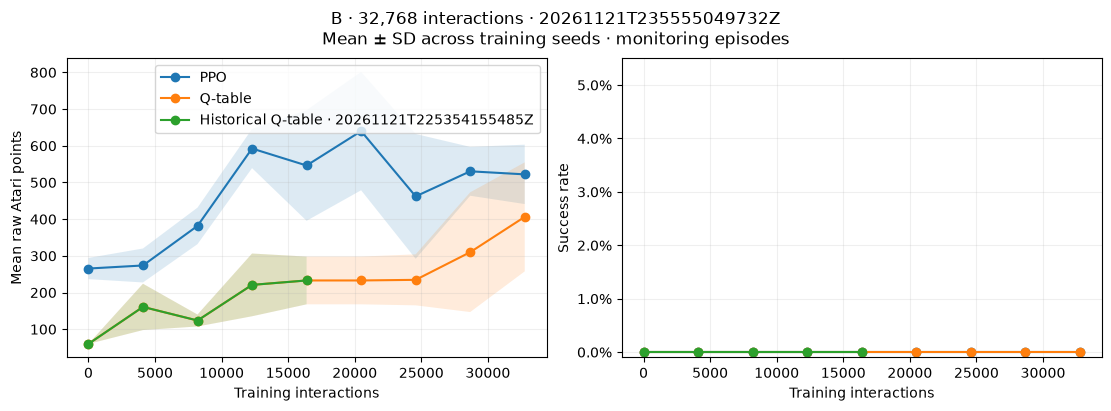

In [9]:
first_results = report(first_stage)

## Valgfri fortsettelse

Sett EXTEND_TO til 65_536 for å fortsette de samme agentene etter standardbudsjettet. Hvis du startet på 16_384, kan du også velge 32_768. Bruk den samme notebook-kjernen.

In [10]:
EXTEND_TO = None  # 65_536, or 32_768 if starting from 16_384
if EXTEND_TO is not None:
    extended_stage = train_to(EXTEND_TO)
    extended_results = report(extended_stage)